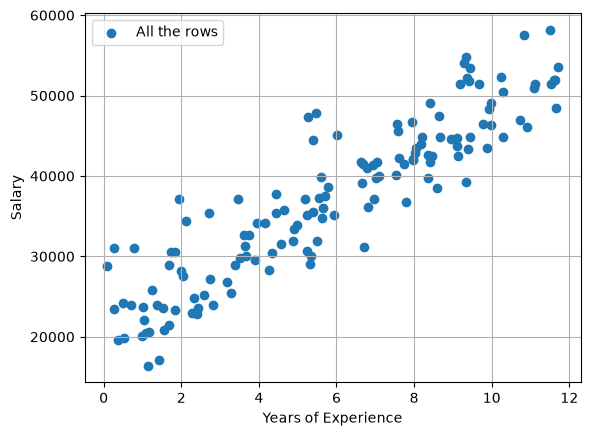

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=140).round(2)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=140)
salaries = pd.DataFrame({'YearsExperience': years, 'Salary': salary.round(-2)})

def plot_regression(X_train, y_train, X_test=None, y_test=None, model=None, label='Training rows'):
    plt.scatter(X_train, y_train, color='tab:blue', label=label)
    if X_test is not None:
        plt.scatter(X_test, y_test, color='tab:orange', label='Test rows')
    if model is not None:
        grid = pd.DataFrame({'YearsExperience': np.linspace(X_train.min(), X_train.max(), num=500).ravel()})
        plt.plot(grid, model.predict(grid), color='tab:red', label='Model')
    plt.xlabel('Years of Experience')
    plt.ylabel('Salary')
    plt.legend()
    plt.grid(True)
    plt.show()

X = salaries[['YearsExperience']]
y = salaries['Salary']
plot_regression(X, y, label='All the rows')

The lines after this show how the model works with train data and the approach to the test data

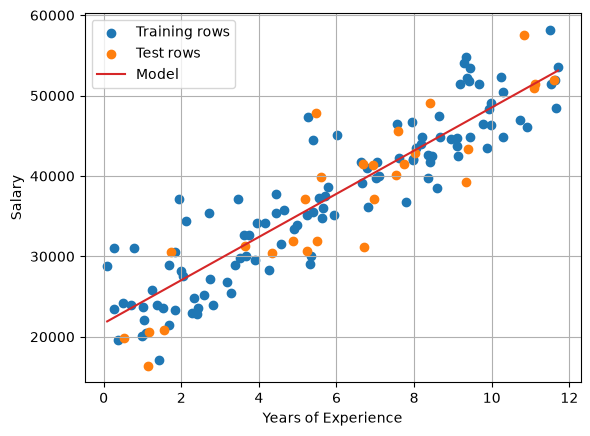

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear_model = LinearRegression().fit(X_train, y_train)
plot_regression(X_train, y_train, X_test, y_test, linear_model)

Now we want to see the training MAE and the test MAE

In [10]:
from sklearn.metrics import mean_absolute_error

def train_and_test_error(model):
    return pd.Series({
            'training MAE': mean_absolute_error(y_train, model.predict(X_train)),
            'test MAE': mean_absolute_error(y_test, model.predict(X_test))
        }).round()

train_and_test_error(linear_model)

training MAE    3147.0
test MAE        3647.0
dtype: float64